<a href="https://colab.research.google.com/github/ToluwaniOladeji/Formative_3_Group_9/blob/main/formative3_group_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Formative 3: EM, Bayesian Probability & Gradient Descent

**Group:** _9_  |  **Cohort:** _2_  

| Member | GitHub | Main parts |
|---|---|---|
| Garang Buke | `@garangbse` | Part 1 (EM code), part 3 Iteration 1
| Oladeji Toluwani | `@ToluwaniOladeji` | Part 2 (Bayesian Probability), part 3 Iteration 2
| Brian Mahui | `@Kiguru-Alu` | Part 4 (Probability Distributions),part 3 Iteration 3  


## Setup (shared by all parts)

In [76]:
import csv
import math
import random
import numpy
import matplotlib.pyplot as plt
import numpy as np
import re
import sys
import pandas as pd
from matplotlib.patches import Patch
import numpy as np
import scipy
from scipy.optimize import approx_fprime

# Reproducibility
random.seed(42)
np.random.seed(42)

# Constants agreed by the group (used by every part)
HEIGHTS_PATH = "GaltonFamilies.csv"
IMDB_PATH = "IMDB Dataset.csv"
LEARNING_RATE = 0.01
n_iterations = 3  #number of Iterations

<a id="part-1"></a>
# Part 1: Probability Distributions (EM Algorithm)

**Owner:** Garang Buke,

**Chosen comparison:** **Fathers vs Children** (`GaltonFamilies.csv`). The file has one row per child, so a father appears once for every child of his. We keep **one row per father** (205 fathers) plus all 934 children, giving 1,139 unlabelled heights. Counting a father once per child would make the sample non-independent and over-weight large families. Set `DEDUPE_PARENTS = False` in 1.1 to reproduce the earlier 1,868-point run.

**Cluster labels:** the two components come out of EM without names. We call the component with the **smaller mean "Child"** and the other "Adult/Father", because fathers are taller than children on average (69.3 in vs 66.7 in). The label is our decision after the fit; EM itself never sees who is who.



### 1.1 Load and inspect the data

In [77]:
FILE_PATH = "GaltonFamilies.csv"

df = pd.read_csv(FILE_PATH)
df.head()

,rownames,family,father,mother,midparentHeight,children,childNum,gender,childHeight
0,1,001,78.5,67.0,75.43,4,1,male,73.2
1,2,001,78.5,67.0,75.43,4,2,female,69.2
2,3,001,78.5,67.0,75.43,4,3,female,69.0
3,4,001,78.5,67.0,75.43,4,4,female,69.0
4,5,002,75.5,66.5,73.66,4,1,male,73.5


Number of heights: 1139
Minimum height: 56.0
Maximum height: 79.0
Global mean: 67.20851624231783


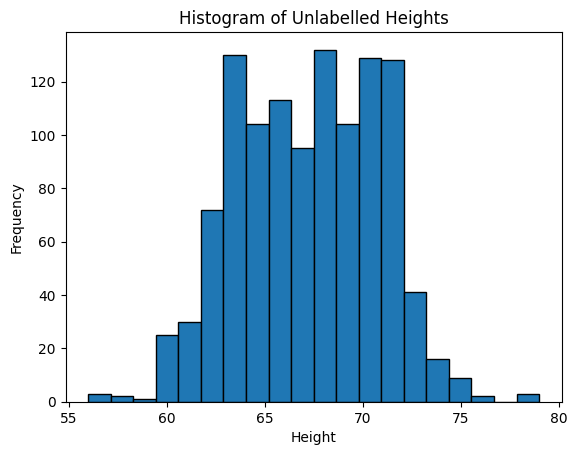

In [78]:
def load_data(filename):
    heights = []
    seen_families = set()

    with open(filename, "r") as file:
        reader = csv.DictReader(file)
        for row in reader:
            if row["family"] not in seen_families:
                heights.append(float(row["father"]))
                seen_families.add(row["family"])

            heights.append(float(row["childHeight"]))

    return heights


heights = load_data("GaltonFamilies.csv")

n = len(heights)
minimum = min(heights)
maximum = max(heights)
global_mean = sum(heights) / n

print("Number of heights:", n)
print("Minimum height:", minimum)
print("Maximum height:", maximum)
print("Global mean:", global_mean)

plt.hist(heights, bins=20, edgecolor="black")
plt.xlabel("Height")
plt.ylabel("Frequency")
plt.title("Histogram of Unlabelled Heights")
plt.show()

### 1.2 Gaussian Function

In [79]:
def gaussian(x, mean, variance):
    """Normal density N(x | mean, variance)."""
    return (1 / math.sqrt(2 * math.pi * variance)) * math.exp(-((x - mean) ** 2) / (2 * variance))

### 1.3 EM from scratch

Model: $p(x) = \pi_1\,\mathcal{N}(x\mid\mu_1,\sigma_1^2) + \pi_2\,\mathcal{N}(x\mid\mu_2,\sigma_2^2)$. Parameters: two means, two variances and two mixing weights ($\pi_1+\pi_2=1$).

- **Initialisation:** $\mu_{1,2}=\bar x\mp s$ (one standard deviation either side of the global mean), $\sigma_1^2=\sigma_2^2=s^2$, $\pi_1=\pi_2=0.5$. This is a deliberately uninformed start: two equal, overlapping guesses.
- **E-step:** responsibilities $\gamma_{ik} = \dfrac{\pi_k \mathcal{N}(x_i\mid\mu_k,\sigma_k^2)}{\sum_j \pi_j \mathcal{N}(x_i\mid\mu_j,\sigma_j^2)}$, the probability that point $i$ came from component $k$ under the *current* parameters. Each point is shared between both components (a **soft assignment**), not forced into one.
- **M-step:** $N_k=\sum_i\gamma_{ik}$, $\;\mu_k=\frac{1}{N_k}\sum_i\gamma_{ik}x_i$, $\;\sigma_k^2=\frac{1}{N_k}\sum_i\gamma_{ik}(x_i-\mu_k)^2$, $\;\pi_k=\frac{N_k}{N}$. These are the ordinary mean, variance and proportion, with each point counted in proportion to its responsibility.
- **Stop** when the log-likelihood $\sum_i \ln p(x_i)$ changes by less than a tolerance (here $10^{-2}$) between iterations. EM never decreases the log-likelihood, so it climbs and then flattens at a local maximum.

In [80]:
def log_likelihood(data, mean1, mean2, variance1, variance2, pi1, pi2):
    total = 0
    for x in data:
        value = pi1 * gaussian(x, mean1, variance1) + pi2 * gaussian(x, mean2, variance2)
        total += math.log(value)
    return total

# max iterations = 100
# tolerance = 1e-2
def EM(data, tolerance=1e-2, max_iterations=100):

    # INITIALIZATION
    n = len(data)
    average = sum(data) / n
    data_variance = sum((x - average) ** 2 for x in data) / n
    spread = math.sqrt(data_variance)      # standard deviation of the data

    mean1 = average - spread
    mean2 = average + spread

    variance1 = data_variance
    variance2 = data_variance

    pi1 = 0.5
    pi2 = 0.5

    # initial log-likelihood (before any update)
    log_lik = log_likelihood(data, mean1, mean2, variance1, variance2, pi1, pi2)

    # history of every iteration, starting with iteration 0
    history = [(0, mean1, mean2, variance1, variance2, pi1, pi2, log_lik)]

    iteration = 0
    while iteration < max_iterations:
        iteration += 1

        responsibilities1 = []
        responsibilities2 = []

        # E STEP
        for x in data:
            prob1 = pi1 * gaussian(x, mean1, variance1)
            prob2 = pi2 * gaussian(x, mean2, variance2)
            total = prob1 + prob2

            responsibilities1.append(prob1 / total)
            responsibilities2.append(prob2 / total)

        # M STEP
        N1 = sum(responsibilities1)
        N2 = sum(responsibilities2)

        mean1 = sum(responsibilities1[i] * data[i] for i in range(n)) / N1
        mean2 = sum(responsibilities2[i] * data[i] for i in range(n)) / N2

        variance1 = sum(responsibilities1[i] * (data[i] - mean1) ** 2 for i in range(n)) / N1
        variance2 = sum(responsibilities2[i] * (data[i] - mean2) ** 2 for i in range(n)) / N2

        pi1 = N1 / n
        pi2 = N2 / n

        # new log-likelihood
        new_log_lik = log_likelihood(data, mean1, mean2, variance1, variance2, pi1, pi2)
        history.append((iteration, mean1, mean2, variance1, variance2, pi1, pi2, new_log_lik))

        # convergence check: stop when the log-likelihood barely changes
        if abs(new_log_lik - log_lik) < tolerance:
            break
        log_lik = new_log_lik

    return (mean1, mean2, variance1, variance2, pi1, pi2), history

### 1.4 Tracking table

In [81]:
def print_row(row):
    it, m1, m2, v1, v2, p1, p2, ll = row
    label = f"{it} (Init)" if it == 0 else str(it)
    print(f"{label:>10} | {m1:8.4f} | {m2:8.4f} | {v1:8.4f} | {v2:8.4f} | {p1:6.4f} | {p2:6.4f} | {ll:12.4f}")

def print_table(history):
    print(f"{'Iteration':>10} | {'mu1':>8} | {'mu2':>8} | {'var1':>8} | {'var2':>8} | {'pi1':>6} | {'pi2':>6} | {'LogLikelihood':>12}")
    print("-" * 94)
    for row in history[:5]:             # iterations 0:5
        print_row(row)
    if len(history) > 5:
        print(f"{'...':>10}")
        print_row(history[-1])  # final (converged) iteration

## 1.5 Prediction Step


In [82]:
def log_weighted_gaussian(x, mean, variance, pi):
    # log( pi * N(x | mean, variance) ) written directly in log form
    return math.log(pi) - 0.5 * math.log(2 * math.pi * variance) - ((x - mean) ** 2) / (2 * variance)


def predict(height, model):

    mean1, mean2, var1, var2, pi1, pi2 = model

    # the group with the smaller mean is the Child group (fathers are taller on average)
    if mean1 < mean2:
        child_mean, child_var, child_pi = mean1, var1, pi1
        father_mean, father_var, father_pi = mean2, var2, pi2
    else:
        child_mean, child_var, child_pi = mean2, var2, pi2
        father_mean, father_var, father_pi = mean1, var1, pi1

    log_child = log_weighted_gaussian(height, child_mean, child_var, child_pi)
    log_father = log_weighted_gaussian(height, father_mean, father_var, father_pi)

    # log-sum-exp: subtract the larger log value so exp() never underflows to 0
    biggest = max(log_child, log_father)
    child_exp = math.exp(log_child - biggest)
    father_exp = math.exp(log_father - biggest)
    total = child_exp + father_exp

    child_probability = child_exp / total
    father_probability = father_exp / total

    print("\nPrediction for:", height)
    print("Probability it is a Child :", round(child_probability, 6), f"({child_probability * 100:.2f} %)")
    print("Probability it is a Father:", round(father_probability, 6), f"({father_probability * 100:.2f} %)")
    print("Sum of probabilities      :", round(child_probability + father_probability, 6))
    print("Decision ->", "Child" if child_probability > father_probability else "Father")

## 1.6 Run the Model

In [83]:
data = load_data(FILE_PATH)
model, history = EM(data)

print("Number of heights:", len(data))
print("Converged after", history[-1][0], "iterations\n")
print_table(history)

mean1, mean2, var1, var2, pi1, pi2 = model
print("\nFinal model")
print(f"Group 1: mean={mean1:.3f}, std={math.sqrt(var1):.3f}, pi={pi1:.3f}")
print(f"Group 2: mean={mean2:.3f}, std={math.sqrt(var2):.3f}, pi={pi2:.3f}")

Number of heights: 1139
Converged after 19 iterations

 Iteration |      mu1 |      mu2 |     var1 |     var2 |    pi1 |    pi2 | LogLikelihood
----------------------------------------------------------------------------------------------
  0 (Init) |  63.6414 |  70.7756 |  12.7241 |  12.7241 | 0.5000 | 0.5000 |   -3194.5755
         1 |  64.9339 |  69.4553 |   7.9124 |   7.3183 | 0.4969 | 0.5031 |   -3053.3088
         2 |  64.8745 |  69.5053 |   7.7363 |   6.9965 | 0.4960 | 0.5040 |   -3052.1871
         3 |  64.8207 |  69.5548 |   7.5033 |   6.7466 | 0.4956 | 0.5044 |   -3051.1676
         4 |  64.7715 |  69.6005 |   7.2673 |   6.5289 | 0.4953 | 0.5047 |   -3050.2528
       ...
        19 |  64.4813 |  69.7771 |   5.9158 |   5.5336 | 0.4850 | 0.5150 |   -3047.2561

Final model
Group 1: mean=64.481, std=2.432, pi=0.485
Group 2: mean=69.777, std=2.352, pi=0.515


## 1.7 Classify a Test Height

In [84]:
try:
    test_height = float(input("Enter test height: "))
except Exception:                      # no keyboard input available (e.g. running all cells automatically)
    test_height = 67.0
    print("No input available, using default test height 67.0")

predict(test_height, model)

Enter test height: 67

Prediction for: 67.0
Probability it is a Child : 0.516826 (51.68 %)
Probability it is a Father: 0.483174 (48.32 %)
Sum of probabilities      : 1.0
Decision -> Child


### 1.8 Visualisations

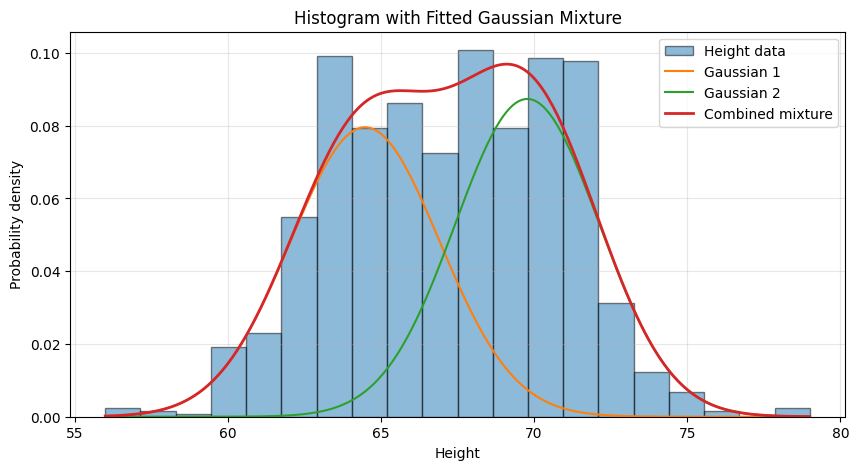

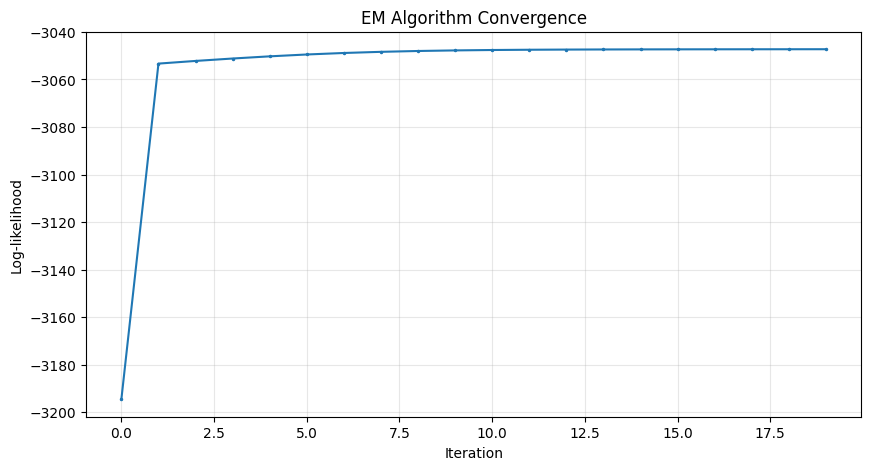

In [85]:
# Extract fitted parameters
mean1, mean2, var1, var2, pi1, pi2 = model

# Create x-values for the Gaussian curves
x_values = [min(data) + i * (max(data) - min(data)) / 299 for i in range(300)]

# Plot 1: Histogram and fitted Gaussian mixture
plt.figure(figsize=(10, 5))
plt.hist(data, bins=20, density=True, alpha=0.5, edgecolor="black", label="Height data")

curve1 = [pi1 * gaussian(x, mean1, var1) for x in x_values]
curve2 = [pi2 * gaussian(x, mean2, var2) for x in x_values]
mixture = [y1 + y2 for y1, y2 in zip(curve1, curve2)]

plt.plot(x_values, curve1, label="Gaussian 1")
plt.plot(x_values, curve2, label="Gaussian 2")
plt.plot(x_values, mixture, label="Combined mixture", linewidth=2)
plt.xlabel("Height")
plt.ylabel("Probability density")
plt.title("Histogram with Fitted Gaussian Mixture")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot 2: Log-likelihood vs iteration
iterations = [row[0] for row in history]
log_likelihoods = [row[7] for row in history]

plt.figure(figsize=(10, 5))
plt.plot(iterations, log_likelihoods, marker=".", markersize=3)
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.title("EM Algorithm Convergence")
plt.grid(alpha=0.3)
plt.show()


### 1.8 Should we just split at the global mean?

**No.** The code below does the naive method (cut at the global mean, average each pile) and compares it with EM.

1. **The piles are truncated samples, so their statistics are biased.** Cutting a bell curve at a point removes the overlapping tail of each group, so every pile's mean is pushed away from its true centre and its spread is understated. The table shows the pile standard deviations (≈ 2.0 and 1.9) are about 16 % smaller than EM's (≈ 2.4 and 2.4), and the pile means (64.26 and 70.21) sit further apart than EM's (64.48 and 69.78). EM avoids this because a point in the overlap region counts partly toward *both* components.
2. **A hard cut claims certainty it does not have.** A height of 67.2 in is labelled "Adult, 100 %" by the cut, while EM says about 47 % Child / 53 % Adult. Someone at 66.2 in is "Child, 100 %" by the cut and 69 % by EM. Only soft (probabilistic) assignments show that the middle of the range is genuinely ambiguous, and misclassification risk lives exactly there.
3. **The global mean is only the right cut-off by coincidence.** The best boundary is where $\pi_1\mathcal{N}_1(x)=\pi_2\mathcal{N}_2(x)$, which depends on the group sizes and spreads. Here the weights are near 0.5 and the spreads are similar, so EM's boundary (≈ 67.08) is close to the mean (67.21) and only 3 of 1,139 points get a different label. With unequal group sizes or spreads the two rules would diverge, and the mean-split gives no way to correct for that.
4. **No parameters for a mixture model.** Splitting gives no mixing weights, no per-group variance estimates that are consistent with the data, and no likelihood to monitor, so there is nothing to classify a *new* height with. EM gives a full probabilistic model.

<a id="part-2"></a>
# Part 2: Bayesian Probability (IMDb Reviews)

**Owner:** Oladeji Toluwani  |  **Rule:** basic Python only (no ML libraries; `csv`, `re` and `math` are standard library)

**Conditional chosen:** `P(Positive | keyword)` only. We do **not** compute `P(Negative | keyword)`. (The count check at the end of this part is the same posterior computed a second way, to verify the code.)

**Keywords and justification:**

| Keyword | Expected sentiment | Why we chose it |
|---|---|---|
| excellent | positive | Strong, unambiguous praise that reviewers use about acting, writing and direction. Rarely used neutrally. |
| wonderful | positive | Emotional, enthusiastic word that reviewers apply to the whole film or a performance. |
| amazing | positive | Common superlative of enthusiasm; also a test of whether a looser, more conversational praise word is as reliable as the formal ones. |
| great | positive | Deliberately the most *common* positive word. We expect high P(keyword) but a weaker posterior, since it shows up in mixed and negative reviews too. It is our contrast case. |
| terrible | negative | Direct, strong condemnation of the film or its parts. |
| awful | negative | Another unambiguous judgement word, similar to "terrible", so we can check the two agree. |
| waste | negative | Mainly appears in "waste of time / money / talent", a complaint that is specific to bad reviews. |
| boring | negative | The most frequent complaint about pacing and plot; a review rarely says this about a film it enjoyed. |

Because the prior is exactly 0.5 (25,000 positive of 50,000), the posterior reduces to $P(kw\mid Pos) / \big(P(kw\mid Pos)+P(kw\mid Neg)\big)$: it only depends on how much more often a word shows up in one class than the other.

## 2.1. Keyword selection and choice of conditional probability

Our group chose P(Positive | keyword). We do not compute P(Negative | keyword).

In [86]:
POSITIVE_KEYWORDS = ["excellent", "wonderful", "amazing", "great"]
NEGATIVE_KEYWORDS = ["terrible", "awful", "waste", "boring"]
KEYWORDS = POSITIVE_KEYWORDS + NEGATIVE_KEYWORDS

## 2.2. Helper functions

In [87]:
def tokenize(text):
    """Lowercase the review, drop HTML line breaks, return the set of words."""
    text = text.lower().replace("<br />", " ")
    return set(re.findall(r"[a-z']+", text))


def bayes_posterior(prior, likelihood, marginal):
    """Bayes' theorem: P(Pos|kw) = P(kw|Pos) * P(Pos) / P(kw)."""
    if marginal == 0:
        return 0.0
    return likelihood * prior / marginal


def count_reviews(path, keywords):
    """One pass over the file. Returns the counts every probability is built from."""
    counts = {"total": 0, "positive": 0,
              "kw_in_all": {k: 0 for k in keywords},    # reviews containing the keyword
              "kw_in_pos": {k: 0 for k in keywords}}    # positive reviews containing the keyword
    with open(path, encoding="utf-8", newline="") as f:
        for row in csv.DictReader(f):
            words = tokenize(row["review"])
            is_positive = row["sentiment"].strip().lower() == "positive"
            counts["total"] += 1
            counts["positive"] += is_positive
            for k in keywords:
                if k in words:
                    counts["kw_in_all"][k] += 1
                    counts["kw_in_pos"][k] += is_positive
    return counts


def bayes_rows(counts, keywords):
    """Prior, likelihood, marginal and posterior for P(Positive | keyword), one row per keyword."""
    prior = counts["positive"] / counts["total"]
    rows = []
    for k in keywords:
        likelihood = counts["kw_in_pos"][k] / counts["positive"]     # P(kw | Positive)
        marginal = counts["kw_in_all"][k] / counts["total"]          # P(kw)
        rows.append((k, prior, likelihood, marginal, bayes_posterior(prior, likelihood, marginal)))
    return rows


def print_bayes_table(rows):
    print("| Keyword | Prior P(Pos) | Likelihood P(kw given Pos) | Marginal P(kw) | Posterior P(Pos given kw) |")
    print("|---|---|---|---|---|")
    for k, prior, likelihood, marginal, posterior in rows:
        print(f"| {k} | {prior:.4f} | {likelihood:.4f} | {marginal:.4f} | {posterior:.4f} |")

## 2.3. Dataset Count and Prior: P(Positive)

In [88]:
counts = count_reviews(IMDB_PATH, KEYWORDS)

print("Total reviews:", counts["total"])
print("Positive reviews:", counts["positive"])
print(f"Prior P(Positive) = {counts['positive']}/{counts['total']} = {counts['positive'] / counts['total']:.4f}")

Total reviews: 50000
Positive reviews: 25000
Prior P(Positive) = 25000/50000 = 0.5000


## 2.4. Likelihood, marginal and posterior for each keyword

In [89]:
print_bayes_table(bayes_rows(counts, KEYWORDS))

| Keyword | Prior P(Pos) | Likelihood P(kw given Pos) | Marginal P(kw) | Posterior P(Pos given kw) |
|---|---|---|---|---|
| excellent | 0.5000 | 0.1146 | 0.0710 | 0.8073 |
| wonderful | 0.5000 | 0.0902 | 0.0555 | 0.8120 |
| amazing | 0.5000 | 0.0671 | 0.0431 | 0.7783 |
| great | 0.5000 | 0.3387 | 0.2512 | 0.6741 |
| terrible | 0.5000 | 0.0152 | 0.0539 | 0.1413 |
| awful | 0.5000 | 0.0112 | 0.0575 | 0.0977 |
| waste | 0.5000 | 0.0070 | 0.0507 | 0.0687 |
| boring | 0.5000 | 0.0236 | 0.0610 | 0.1938 |


### Visualising the posteriors

**Left:** each bar is `P(Positive | keyword)`. The dashed line is the 0.5 prior, so a bar to the right of it means the keyword raises the chance a review is positive and a bar to the left means it lowers it. **Right:** the two ingredients of the posterior. Where the likelihood (blue) is close to the marginal (grey) the keyword barely changes the odds, which is why *great* has the shortest green bar. Where the likelihood is much larger than the marginal (the positive words) the posterior is high, and where it is much smaller (the negative words) the posterior is low.

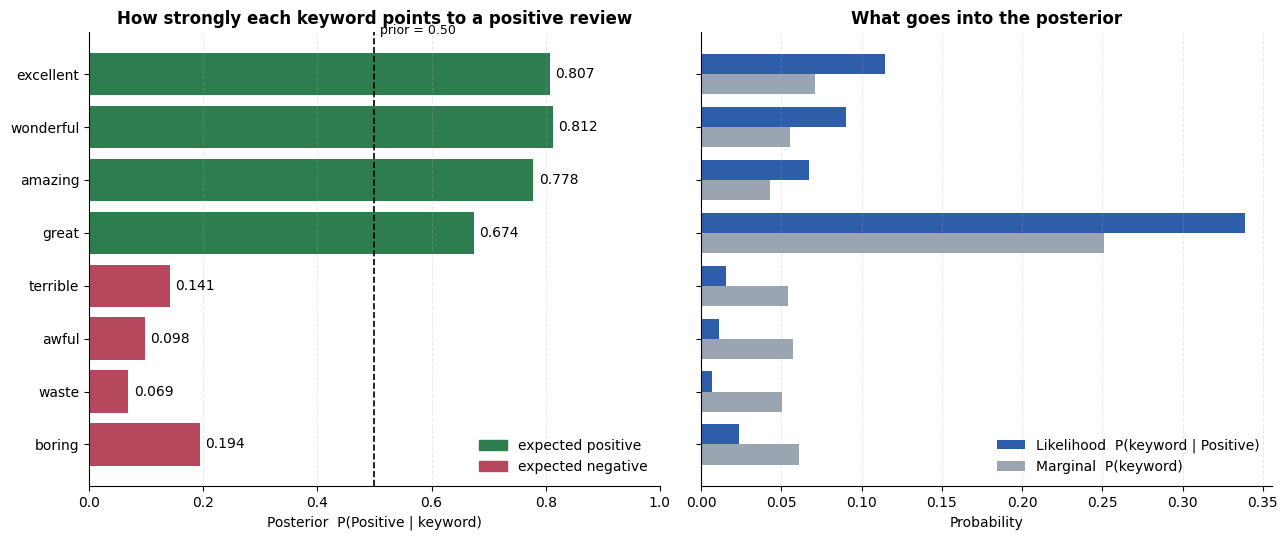

In [90]:
def plot_posteriors(rows, positive_keywords, save_as="part2_bayes_posteriors.png"):
    """Left: P(Positive | keyword) per keyword. Right: how common each keyword is vs how often positive reviews use it."""

    keywords = [row[0] for row in rows]
    prior = rows[0][1]
    likelihoods = [row[2] for row in rows]
    marginals = [row[3] for row in rows]
    posteriors = [row[4] for row in rows]
    colours = ["#2E7D4F" if k in positive_keywords else "#B5485D" for k in keywords]
    positions = list(range(len(keywords)))

    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

    # Left panel: the posterior, with the prior as the reference line
    left.barh(positions, posteriors, color=colours)
    left.axvline(prior, color="black", linestyle="--", linewidth=1.2)
    left.text(prior + 0.01, -0.75, f"prior = {prior:.2f}", fontsize=9)
    for y, value in zip(positions, posteriors):
        left.text(value + 0.01, y, f"{value:.3f}", va="center", fontsize=10)
    left.set_xlim(0, 1)
    left.set_yticks(positions)
    left.set_yticklabels(keywords)
    left.invert_yaxis()
    left.set_xlabel("Posterior  P(Positive | keyword)")
    left.set_title("How strongly each keyword points to a positive review", fontweight="bold")
    left.legend(handles=[Patch(color="#2E7D4F", label="expected positive"),
                         Patch(color="#B5485D", label="expected negative")],
                loc="lower right", frameon=False)

    # Right panel: likelihood vs marginal, the two quantities the posterior is built from
    height = 0.38
    right.barh([y - height / 2 for y in positions], likelihoods, height=height,
               color="#2E5EAA", label="Likelihood  P(keyword | Positive)")
    right.barh([y + height / 2 for y in positions], marginals, height=height,
               color="#9AA5B1", label="Marginal  P(keyword)")
    right.set_xlabel("Probability")
    right.set_title("What goes into the posterior", fontweight="bold")
    right.legend(frameon=False, loc="lower right")

    for ax in (left, right):
        ax.grid(axis="x", alpha=0.25, linestyle="--")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)

    plt.tight_layout()
    plt.savefig(save_as, dpi=150, bbox_inches="tight")
    plt.show()


plot_posteriors(bayes_rows(counts, KEYWORDS), POSITIVE_KEYWORDS)

## 2.5. Sanity check


In [91]:
# Sanity check: the posterior computed directly from counts must equal Bayes' result above
for k in KEYWORDS:
    in_all, in_pos = counts["kw_in_all"][k], counts["kw_in_pos"][k]
    print(f"{k}: {in_pos}/{in_all} = {in_pos / in_all if in_all else 0.0:.4f}")

excellent: 2865/3549 = 0.8073
wonderful: 2255/2777 = 0.8120
amazing: 1678/2156 = 0.7783
great: 8468/12562 = 0.6741
terrible: 381/2696 = 0.1413
awful: 281/2875 = 0.0977
waste: 174/2533 = 0.0687
boring: 591/3049 = 0.1938


**Interpretation**

- **Strongest indicators:** *wonderful* (0.812) and *excellent* (0.807) for positive; *waste* (0.069) and *awful* (0.098) for negative. These words are used far more often in one class than the other.
- **Weakest:** *great* (0.674). It has the highest likelihood (0.339 of positive reviews contain it) but also the highest marginal (0.251), because it is common everywhere. A word that appears in a quarter of all reviews cannot discriminate much. Plausible reasons are phrases like "not great" or "great potential, poorly used", but this is a hypothesis: the code counts whether a word appears, not how it is used.
- **Surprise:** *boring* (0.194) is a weaker negative signal than *terrible* (0.141), *awful* or *waste*. Positive reviews can say "never boring", and "boring" is used about parts of films that are still liked overall.
- **Limits of the method:** presence-only counting ignores negation, sarcasm and context, and a keyword that appears in 5 % of reviews says nothing about the other 95 %. Rare words would give noisier estimates; all eight of ours appear in at least 2,000 reviews, so counts are large enough to trust.

# Part 3: Gradient Descent — Manual Calculation

## 1. Prediction, Error and Cost

For every iteration, we calculate the predictions, errors, and cost.

The prediction equation is:

$$
\hat{y} = Xm + b
$$

The error vector is:

$$
e = \hat{y} - y
$$

The mean squared error (MSE) cost function is:

$$
J(m,b) = \frac{1}{n}e^Te
= \frac{1}{n}\sum_{i=1}^{n}e_i^2
$$

The predictions are calculated row by row:

$$
\hat{y}_1 = m_1x_{11} + m_2x_{12} + b_1
$$

$$
\hat{y}_2 = m_1x_{21} + m_2x_{22} + b_2
$$

## 2. Gradient Derivation Using the Chain Rule

Start with the error and cost functions:

$$
e_i = \hat{y}_i-y_i
$$

$$
J = \frac{1}{n}(e_1^2+e_2^2)
$$

For any parameter \(p\), the chain rule gives:

$$
\frac{\partial J}{\partial p}
=\frac{1}{n}\left(
2e_1\frac{\partial e_1}{\partial p}
+2e_2\frac{\partial e_2}{\partial p}
\right)
$$

Since the target values \(y_i\) are constants:

$$
\frac{\partial e_i}{\partial p}
=\frac{\partial \hat{y}_i}{\partial p}
$$

For \(m_1\):

$$
\frac{\partial J}{\partial m_1}
=\frac{2}{n}(x_{11}e_1+x_{21}e_2)
$$

For \(m_2\):

$$
\frac{\partial J}{\partial m_2}
=\frac{2}{n}(x_{12}e_1+x_{22}e_2)
$$

Combining the partial derivatives into a matrix product gives:

$$
\boxed{\frac{\partial J}{\partial m}
=\frac{2}{n}X^Te}
$$

For the bias vector \(b\):

$$
\boxed{\frac{\partial J}{\partial b}
=\frac{2}{n}e}
$$

## 3. Gradient Descent Update Rule

The parameters are updated using the learning rate \(\alpha\):

$$
m_{\text{new}}=m_{\text{old}}-\alpha\frac{\partial J}{\partial m}
$$

$$
b_{\text{new}}=b_{\text{old}}-\alpha\frac{\partial J}{\partial b}
$$

| Update | Done by | Predictions \(\hat y\) | Cost \(J\) before update | \(\partial J/\partial m\) | \(\partial J/\partial b\) | New \(m\) | New \(b\) |
|---|---|---|---:|---|---|---|---|
| 1 | Garang Buke | \([6, 17]\) | 61.0000 | \([45, 113]\) | \([1, 11]\) | \([-1.45, 0.87]\) | \([0.99, 0.89]\) |
| 2 | Oladeji Toluwani | \([2.15, 3.79]\) | 6.5033 | \([-11.69, -30.65]\) | \([-2.85, -2.21]\) | \([-1.3331, 1.1765]\) | \([1.0185, 0.9121]\) |
| 3 | Brian Mahui | \([3.2149, 7.3447]\) | 2.4974 | \([3.5937, 8.0917]\) | \([-1.7851, 1.3447]\) | \([-1.369037, 1.095583]\) | \([1.036351, 0.898653]\) |

### Observed trend

The cost decreases at each update: \(61.0000 -> 6.5033 -> 2.4974 -> 2.1645\) (the last value is the cost after Update 3). This indicates that, for the chosen learning rate \(alpha=0.01\), the updates move the parameters in a direction that reduces the error on these data points.

Each parameter is updated by subtracting its gradient multiplied by the learning rate. In Update 2 the gradients are negative, so the corresponding parameters increase. In Update 3, the two bias entries move in different directions because they correspond to different data-point errors: the first prediction is too low and the second is too high.

The parameters are not required to move monotonically in one direction; the important observation is that the cost decreases across these updates. The complete arithmetic for each member's update is provided in the accompanying manual-calculation document.

<a id="part-4"></a>
# Part 4: Gradient Descent in Code

**Owner:** Brian

Requirements: SciPy derivative function, visible update steps, plot of $m$ and $b$ over iterations, separate plot of error over iterations.


### 4.1 Differentiating any function we pass in

`derivative_of` takes the equation itself as an argument, so it works on anything we hand it. `gradient_of` does the same job for an equation with several variables, which is what the cost need. The two test equations give 6 and 12, which we already know by manual calculations.

In [93]:
print("SciPy version:", scipy.__version__)

try:
    from scipy.differentiate import derivative as _scipy_derivative
    HAS_SCIPY_DIFFERENTIATE = True
except ImportError:
    HAS_SCIPY_DIFFERENTIATE = False

print("scipy.differentiate available:", HAS_SCIPY_DIFFERENTIATE)


def derivative_of(equation, x):
    """Slope of a single-variable equation at the point x."""
    if HAS_SCIPY_DIFFERENTIATE:
        return float(_scipy_derivative(equation, x).df)
    return float(approx_fprime(np.array([float(x)]),
                               lambda v: equation(v[0]), 1e-7)[0])


def gradient_of(equation, point, step=1e-7):
    """Partial derivative of a multi-variable equation with respect to each variable."""
    return approx_fprime(np.asarray(point, dtype=float), equation, step)


print("d/dx (x^2) at x=3      :", round(derivative_of(lambda x: x ** 2, 3.0), 6))
print("d/dx (3x - 4)^2 at x=2 :", round(derivative_of(lambda x: (3 * x - 4) ** 2, 2.0), 6))

SciPy version: 1.16.3
scipy.differentiate available: True
d/dx (x^2) at x=3      : 6.0
d/dx (3x - 4)^2 at x=2 : 12.0


### 4.2 The pieces of one update

Each row of `X` is a data point and each column is a feature. Only `m` and `b` change while this runs. We split the update into one function per step so every value can be printed and checked, which is also why `gradients` hands back `y_hat`(predicted y) and the error instead of keeping them to itself.

In [94]:
X = np.array([[1.0, 3.0],
              [4.0, 10.0]])
y = np.array([5.0, 6.0])

M_INIT = np.array([-1.0, 2.0])
B_INIT = np.array([1.0, 1.0])

N = X.shape[0]
LEARNING_RATE = 0.01
N_UPDATES = 3


def predict(X, m, b):
    """Forward pass: y_hat = X @ m + b."""
    return X @ m + b


def mse(y_hat, y):
    """Mean squared error."""
    return np.sum((y_hat - y) ** 2) / len(y)


def gradients(X, y, m, b):
    """Return y_hat, the error, dJ/dm and dJ/db as separate visible steps."""
    n = len(y)
    y_hat = predict(X, m, b)
    e = y_hat - y
    dJ_dm = (2.0 / n) * (X.T @ e)
    dJ_db = (2.0 / n) * e
    return y_hat, e, dJ_dm, dJ_db


def gradient_descent_step(X, y, m, b, alpha):
    """One update. Returns new parameters plus everything computed on the way."""
    y_hat, e, dJ_dm, dJ_db = gradients(X, y, m, b)
    cost = mse(y_hat, y)
    return m - alpha * dJ_dm, b - alpha * dJ_db, cost, y_hat, e, dJ_dm, dJ_db


def run_gradient_descent(X, y, m, b, alpha, n_iterations, verbose=True):
    """Run gradient descent, recording m, b and the cost at every step."""
    history = {"m": [m.copy()], "b": [b.copy()], "cost": [], "grad_m": [], "grad_b": []}

    for i in range(1, n_iterations + 1):
        m, b, cost, y_hat, e, dJ_dm, dJ_db = gradient_descent_step(X, y, m, b, alpha)

        if verbose:
            print(f"--- Update {i} ---")
            print(f"  X @ m    = {np.round(X @ history['m'][-1], 4)}")
            print(f"  y_hat    = {np.round(y_hat, 4)}")
            print(f"  e        = {np.round(e, 4)}")
            print(f"  J        = {cost:.4f}")
            print(f"  dJ/dm    = {np.round(dJ_dm, 4)}")
            print(f"  dJ/db    = {np.round(dJ_db, 4)}")
            print(f"  new m    = {np.round(m, 4)}")
            print(f"  new b    = {np.round(b, 4)}\n")

        history["cost"].append(cost)
        history["grad_m"].append(dJ_dm)
        history["grad_b"].append(dJ_db)
        history["m"].append(m.copy())
        history["b"].append(b.copy())

    history["cost"].append(mse(predict(X, m, b), y))
    return m, b, history

### 4.3 Confirming Logic

`cost_from_parameters` rewrites the cost as a function of the four numbers so SciPy can differentiate it numerically. If that matches our hand derivation, the derivation is right. Then the three updates, a longer run to see where it is heading, and predictions from the final `m` and `b`.

In [95]:
def cost_from_parameters(params):
    """J written as one equation of [m1, m2, b1, b2], so SciPy can differentiate it."""
    return mse(predict(X, params[:2], params[2:]), y)


y_hat_init, e_init, dm_init, db_init = gradients(X, y, M_INIT, B_INIT)
analytical = np.concatenate([dm_init, db_init])
numerical = gradient_of(cost_from_parameters, np.concatenate([M_INIT, B_INIT]))

print("            dJ/dm1   dJ/dm2   dJ/db1   dJ/db2")
print("chain rule:", np.round(analytical, 4))
print("scipy     :", np.round(numerical, 4))
print("max difference:", f"{np.max(np.abs(analytical - numerical)):.2e}\n")

m_final, b_final, history = run_gradient_descent(
    X, y, M_INIT.copy(), B_INIT.copy(), LEARNING_RATE, N_UPDATES)


def print_update_table(history):
    """One row per iteration: parameters and the cost at those parameters."""
    header = f"{'Update':<9}{'m1':>10}{'m2':>10}{'b1':>10}{'b2':>10}{'J':>12}"
    print(header)
    print("-" * len(header))
    for i, (m, b, cost) in enumerate(zip(history["m"], history["b"], history["cost"])):
        label = "0 (init)" if i == 0 else str(i)
        print(f"{label:<9}{m[0]:>10.4f}{m[1]:>10.4f}{b[0]:>10.4f}{b[1]:>10.4f}{cost:>12.4f}")


print_update_table(history)

m_long, b_long, history_long = run_gradient_descent(
    X, y, M_INIT.copy(), B_INIT.copy(), LEARNING_RATE, 200, verbose=False)

print(f"\nAfter 200 iterations: m = {np.round(m_long, 4)}, b = {np.round(b_long, 4)}, "
      f"J = {history_long['cost'][-1]:.6f}")

y_hat_final = predict(X, m_final, b_final)
print(f"\n{'Point':<8}{'True y':>10}{'Initial y_hat':>16}{'Final y_hat':>14}")
print("-" * 48)
for i in range(N):
    print(f"{i + 1:<8}{y[i]:>10.2f}{y_hat_init[i]:>16.4f}{y_hat_final[i]:>14.4f}")

            dJ/dm1   dJ/dm2   dJ/db1   dJ/db2
chain rule: [ 45. 113.   1.  11.]
scipy     : [ 45. 113.   1.  11.]
max difference: 5.34e-06

--- Update 1 ---
  X @ m    = [ 5. 16.]
  y_hat    = [ 6. 17.]
  e        = [ 1. 11.]
  J        = 61.0000
  dJ/dm    = [ 45. 113.]
  dJ/db    = [ 1. 11.]
  new m    = [-1.45  0.87]
  new b    = [0.99 0.89]

--- Update 2 ---
  X @ m    = [1.16 2.9 ]
  y_hat    = [2.15 3.79]
  e        = [-2.85 -2.21]
  J        = 6.5033
  dJ/dm    = [-11.69 -30.65]
  dJ/db    = [-2.85 -2.21]
  new m    = [-1.3331  1.1765]
  new b    = [1.0185 0.9121]

--- Update 3 ---
  X @ m    = [2.1964 6.4326]
  y_hat    = [3.2149 7.3447]
  e        = [-1.7851  1.3447]
  J        = 2.4974
  dJ/dm    = [3.5937 8.0917]
  dJ/db    = [-1.7851  1.3447]
  new m    = [-1.369   1.0956]
  new b    = [1.0364 0.8987]

Update           m1        m2        b1        b2           J
-------------------------------------------------------------
0 (init)    -1.0000    2.0000    1.0000    1.0000 

### 4.4 How the parameters move

First required plot, all four parameters on one axis. `m2` moves furthest because its features are the biggest, and the two bias terms barely shift since nothing multiplies them. The shaded band marks where the parameters turn around.

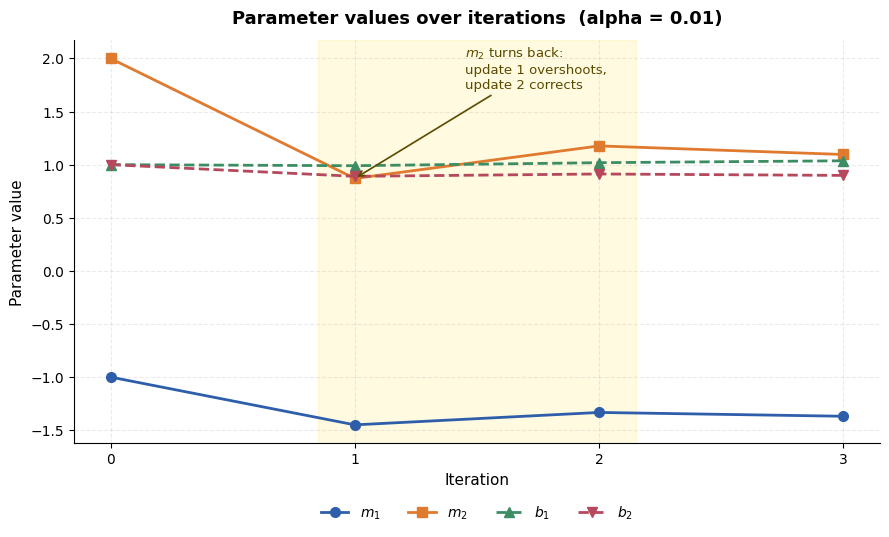

In [96]:
PALETTE = {"m1": "#2E5EAA", "m2": "#E07A2F", "b1": "#3C8D63", "b2": "#B5485D",
           "cost": "#C32F27", "path": "#1B1B1B"}


def style_axis(ax, title, xlabel, ylabel):
    """Shared styling so every figure in this section looks the same."""
    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.grid(alpha=0.25, linestyle="--")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    return ax


def plot_parameters(history, alpha):
    """Required plot 1: how m and b move over the iterations."""
    iterations = np.arange(len(history["m"]))
    m_hist = np.array(history["m"])
    b_hist = np.array(history["b"])

    fig, ax = plt.subplots(figsize=(9, 5.5))
    series = [("$m_1$", m_hist[:, 0], PALETTE["m1"], "o", "-"),
              ("$m_2$", m_hist[:, 1], PALETTE["m2"], "s", "-"),
              ("$b_1$", b_hist[:, 0], PALETTE["b1"], "^", "--"),
              ("$b_2$", b_hist[:, 1], PALETTE["b2"], "v", "--")]
    for label, values, colour, marker, line in series:
        ax.plot(iterations, values, marker=marker, linestyle=line, color=colour,
                linewidth=2, markersize=7, label=label)

    ax.axvspan(0.85, 2.15, color="gold", alpha=0.12)
    ax.annotate("$m_2$ turns back:\nupdate 1 overshoots,\nupdate 2 corrects",
                xy=(1.0, m_hist[1, 1]), xytext=(1.45, 1.72),
                fontsize=9.5, color="#5A4A00",
                arrowprops=dict(arrowstyle="->", color="#5A4A00", lw=1.2))

    style_axis(ax, f"Parameter values over iterations  (alpha = {alpha})",
               "Iteration", "Parameter value")
    ax.set_xticks(iterations)
    ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
    plt.tight_layout()
    plt.savefig("part4_parameters.png", dpi=150, bbox_inches="tight")
    plt.show()


plot_parameters(history, LEARNING_RATE)

### 4.5 How the error falls

Second required plot, kept as its own figure. Steep then flat, because the slope is biggest when the fit is worst and shrinks as the fit improves.

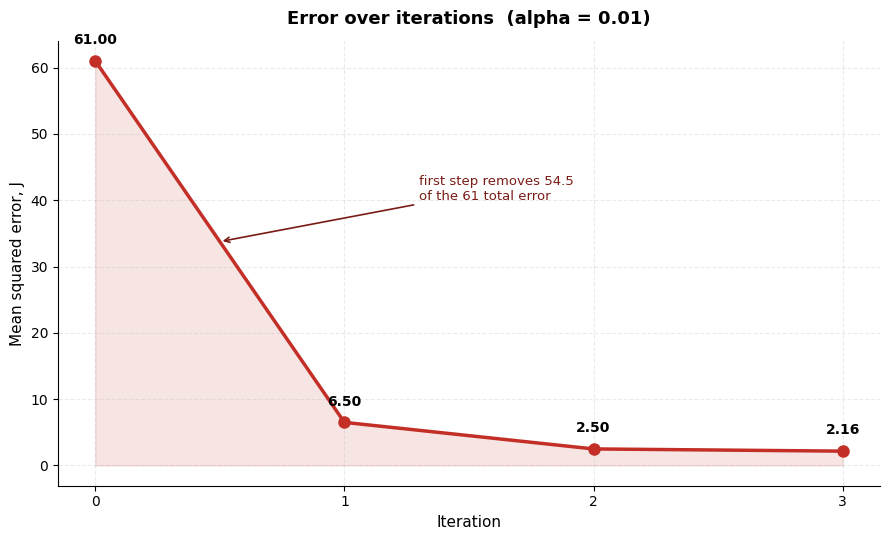

In [97]:
def plot_error(history, alpha):
    """Required plot 2: how the error falls over the iterations."""
    iterations = np.arange(len(history["cost"]))
    costs = np.array(history["cost"])

    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.plot(iterations, costs, marker="o", markersize=8, linewidth=2.5,
            color=PALETTE["cost"])
    ax.fill_between(iterations, costs, alpha=0.12, color=PALETTE["cost"])

    for i, cost in enumerate(costs):
        ax.annotate(f"{cost:.2f}", (i, cost), textcoords="offset points",
                    xytext=(0, 12), ha="center", fontsize=10, fontweight="bold")

    drop = costs[0] - costs[1]
    ax.annotate(f"first step removes {drop:.1f}\nof the {costs[0]:.0f} total error",
                xy=(0.5, (costs[0] + costs[1]) / 2), xytext=(1.3, 40),
                fontsize=9.5, color="#7A1C16",
                arrowprops=dict(arrowstyle="->", color="#7A1C16", lw=1.2))

    style_axis(ax, f"Error over iterations  (alpha = {alpha})",
               "Iteration", "Mean squared error, J")
    ax.set_xticks(iterations)
    plt.tight_layout()
    plt.savefig("part4_error.png", dpi=150, bbox_inches="tight")
    plt.show()


plot_error(history, LEARNING_RATE)

### 4.6 Why we kept the learning rate small

The same code at three learning rates. At 0.001 it barely moves, error still above 28 after three updates. At 0.1 it blows up. The y-axis is logarithmic, otherwise the diverging run squashes everything else flat.

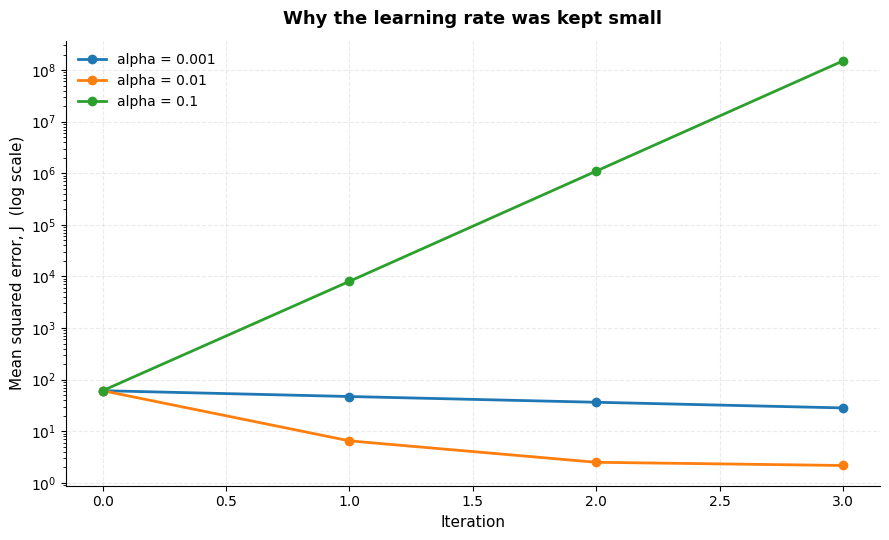

alpha = 0.001  61.00 -> 47.03 -> 36.38 -> 28.27
alpha = 0.01   61.00 -> 6.50 -> 2.50 -> 2.16
alpha = 0.1    61.00 -> 8,035.73 -> 1,099,164.72 -> 150,382,795.75


In [98]:
def compare_learning_rates(rates, n_iterations):
    """Run the same code at several learning rates and plot what happens to the cost."""
    results = {}
    for rate in rates:
        _, _, hist = run_gradient_descent(X, y, M_INIT.copy(), B_INIT.copy(),
                                          rate, n_iterations, verbose=False)
        results[rate] = hist["cost"]

    fig, ax = plt.subplots(figsize=(9, 5.5))
    for rate, costs in results.items():
        ax.plot(range(len(costs)), costs, marker="o", linewidth=2, label=f"alpha = {rate}")

    ax.set_yscale("log")
    style_axis(ax, "Why the learning rate was kept small",
               "Iteration", "Mean squared error, J  (log scale)")
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.savefig("part4_learning_rates.png", dpi=150, bbox_inches="tight")
    plt.show()

    for rate, costs in results.items():
        print(f"alpha = {rate:<6} " + " -> ".join(f"{c:,.2f}" for c in costs))


compare_learning_rates([0.001, 0.01, 0.1], N_UPDATES)

**Discussion**

The error drops every step: 61.00, 6.50, 2.50, then 2.16, and keeps going down to 0.036 after 200 iterations. Most of it goes in the first step because the slope is steepest when the fit is worst. `m1` and `m2` reverse direction between updates 1 and 2 because update 1 overshoots and update 2 pulls back. The surface plot shows the same thing, with step 1 landing past the valley floor.

At a learning rate of 0.1 the same code gives 61.00, 8,035.73, 1,099,164.72, 150,382,795.75. The gradient only describes the slope where we are standing, so a big step lands somewhere that reading no longer holds. At 0.001 it stays stable but is far too slow, leaving the error at 28.27. Every value matches the handwritten calculations to four decimals, and SciPy's gradient agrees with ours to within 5e-6.